# 24 · Real-data forecasts

Can the same pipeline learn from a real series without seeing its future? Fit scaled Ridge and simple baselines on four historical prefixes of AirPassengers, compare their points together, then inspect a probabilistic forecast.

From the repository root, install `python -m pip install -e '.[notebooks]'`, then launch `python -m jupyterlab notebooks`. Use that Python kernel and run all cells in order. See the [notebook guide](README.md). This application is self-contained and runs locally. Data are bundled; no downloads are needed.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

from timegym import Case, ForecastTask, Pipeline, NaiveForecaster, GaussianAR1Forecaster, TestReport
from timegym.diagnostics import evaluate_forecast
from timegym.metrics import mase
from timegym.models import SklearnForecaster

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'pyproject.toml').is_file() and (p / 'timegym').is_dir())
plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})


## Load monthly passenger counts

AirPassengers records 144 monthly international passenger counts, in thousands, from January 1949 to December 1960. See the [official R description](https://stat.ethz.ch/R-manual/R-devel/library/datasets/html/AirPassengers.html) and [source/licensing record](../experiments/data/README.md).

Use an explicit monthly index rather than rounding fractional CSV dates. The checksum fixes the teaching dataset; plots and MAE retain thousands of passengers.

In [2]:
data_path = ROOT / 'experiments' / 'data' / 'AirPassengers.csv'
source_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
expected_sha256 = 'bdb98adbd418a6de6842a742e0602f363c3b841c26677e7e61a1e055e9509bd8'
assert source_sha256 == expected_sha256
raw = pd.read_csv(data_path)
series = pd.DataFrame({'passengers': raw['value'].to_numpy(dtype=float)},
                      index=pd.period_range('1949-01', periods=len(raw), freq='M'))
assert len(series) == 144 and series.index[-1] == pd.Period('1960-12', freq='M')
display(series.head())
print('Dataset SHA-256:', source_sha256)


,passengers
1949-01,112.0
1949-02,118.0
1949-03,132.0
1949-04,129.0
1949-05,121.0


Dataset SHA-256: bdb98adbd418a6de6842a742e0602f363c3b841c26677e7e61a1e055e9509bd8


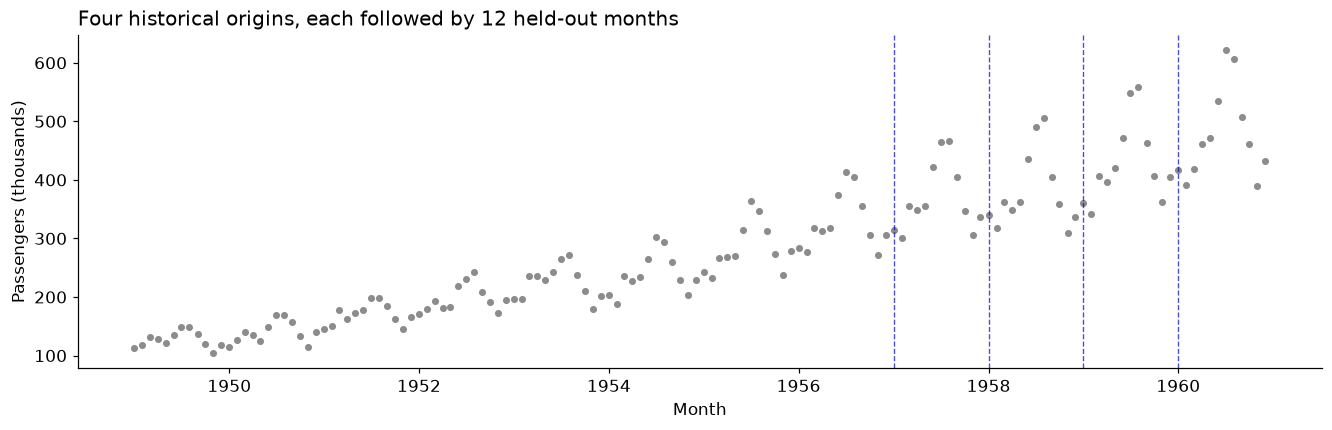

In [3]:
origin_lengths = (96, 108, 120, 132)
horizon = 12
fig, ax = plt.subplots(figsize=(12, 3.8), layout='constrained')
ax.scatter(series.index.to_timestamp(), series['passengers'], color='0.55', s=13)
for n in origin_lengths:
    ax.axvline(series.index[n].to_timestamp(), color='#0000CC', linestyle='--', linewidth=0.9, alpha=0.7)
ax.set(title='Four historical origins, each followed by 12 held-out months',
       xlabel='Month', ylabel='Passengers (thousands)')
plt.show()

## Hold out the future at each origin

The contexts end in December 1956–1959, each followed by a 12-month holdout. Later origins can use observations that have become history. These are four windows from **one series**, not independent datasets. Set `reference=None`: real holdouts do not supply an analytic conditional mean or covariance.

In [4]:
cases = []
for n in origin_lengths:
    context = series.iloc[:n].copy()
    heldout = series.iloc[n:n + horizon].copy()
    case = Case(task=ForecastTask(context=context, future_index=heldout.index.copy()),
                observed=heldout, reference=None,
                manifest={'kind': 'AirPassengers', 'seed': None,
                          'origin': str(context.index[-1]), 'context_length': n,
                          'horizon': horizon, 'target_names': ['passengers'],
                          'source_sha256': source_sha256})
    cases.append(case)
display(pd.DataFrame([{'origin': str(c.task.context.index[-1]),
                       'training_rows': len(c.task.context),
                       'holdout_start': str(c.task.future_index[0]),
                       'holdout_end': str(c.task.future_index[-1])} for c in cases]))


,origin,training_rows,holdout_start,holdout_end
0,1956-12,96,1957-01,1957-12
1,1957-12,108,1958-01,1958-12
2,1958-12,120,1959-01,1959-12
3,1959-12,132,1960-01,1960-12


## Build lagged training examples

Each input contains the preceding 12 context values and predicts the next context value. Scaling and Ridge fit these training rows. For future steps, the recursive reducer appends its predictions, never held-out observations. Inspect the first few training windows below.

In [5]:
window = 12
first_context = cases[0].task.context
values = first_context.to_numpy()
lag_features = np.asarray([values[i - window:i].ravel()
                           for i in range(window, len(values))])
training_targets = values[window:, 0]
assert lag_features.shape == (len(first_context) - window, window)
assert first_context.index[-1] < cases[0].task.future_index[0]
print('Training feature matrix:', lag_features.shape)
print('Training labels:', training_targets.shape)
display(pd.DataFrame({'oldest_lag_month': first_context.index[:3].astype(str),
                      'newest_lag_month': first_context.index[window - 1:window + 2].astype(str),
                      'target_month': first_context.index[window:window + 3].astype(str),
                      'target_value': training_targets[:3]}))


Training feature matrix: (84, 12)
Training labels: (84,)


,oldest_lag_month,newest_lag_month,target_month,target_value
0,1949-01,1949-12,1950-01,115.0
1,1949-02,1950-01,1950-02,126.0
2,1949-03,1950-02,1950-03,141.0


## Fit three point baselines

Historical mean uses the full prefix; seasonal naive repeats its final 12 months; Ridge uses a fixed, untuned `alpha=1.0`. The adapter clones estimator templates before each fit.

Default MASE uses lag-one scaling. We also report seasonal **MASE(12)**, whose denominator uses only that origin's context. Keep the two definitions separate.

In [6]:
scaler_template = StandardScaler()
ridge_template = Ridge(alpha=1.0)
ridge_pipeline = Pipeline(window_length=window).add(scaler_template).add(ridge_template)
models = {'Historical mean': Pipeline(NaiveForecaster(strategy='mean')),
          'Seasonal naive': Pipeline(NaiveForecaster(strategy='seasonal', period=12)),
          'Scaled Ridge': ridge_pipeline}
forecasts, results, score_rows = {}, {}, []
for case_index, case in enumerate(cases):
    for model_name, model in models.items():
        forecast = model.predict(case.task.context, case.task.future_index)
        result = evaluate_forecast(case, forecast)
        result.manifest['model'] = model_name
        assert not any(d.status in {'FAIL', 'ERROR'} for d in result.diagnostics)
        assert 'mean_reference_mse' not in result.metrics
        forecasts[(case_index, model_name)] = forecast
        results[(case_index, model_name)] = result
        score_rows.append({'origin': str(case.task.context.index[-1]), 'model': model_name,
                           'MAE': result.metrics['mae'], 'MASE(1)': result.metrics['mase'],
                           'MASE(12)': mase(case.observed.to_numpy(), forecast.point,
                                            case.task.context.to_numpy(), seasonality=12)})
scores = pd.DataFrame(score_rows)
assert not hasattr(scaler_template, 'mean_')
assert not hasattr(ridge_template, 'coef_')
display(scores.round(3))


,origin,model,MAE,MASE(1),MASE(12)
0,1956-12,Historical mean,154.708,8.276,5.298
1,1956-12,Seasonal naive,40.167,2.149,1.375
2,1956-12,Scaled Ridge,10.305,0.551,0.353
3,1957-12,Historical mean,150.102,7.388,4.910
4,1957-12,Seasonal naive,12.583,0.619,0.412
5,1957-12,Scaled Ridge,36.420,1.793,1.191
6,1958-12,Historical mean,182.425,8.232,6.384
7,1958-12,Seasonal naive,47.333,2.136,1.657
8,1958-12,Scaled Ridge,16.916,0.763,0.592
9,1959-12,Historical mean,213.674,8.872,7.017


## Compare origins side by side

Inspect errors and forecast points together. These selected windows provide descriptive comparisons, not an independent-sample ranking or a tuning set with unbiased final evaluation.

In [7]:
display(scores.pivot(index='origin', columns='model', values='MAE').round(2))
display(scores.pivot(index='origin', columns='model', values='MASE(12)').round(3))


model,Historical mean,Scaled Ridge,Seasonal naive
origin,,,
1956-12,154.71,10.30,40.17
1957-12,150.10,36.42,12.58
1958-12,182.43,16.92,47.33
1959-12,213.67,14.37,47.83


model,Historical mean,Scaled Ridge,Seasonal naive
origin,,,
1956-12,5.298,0.353,1.375
1957-12,4.910,1.191,0.412
1958-12,6.384,0.592,1.657
1959-12,7.017,0.472,1.571


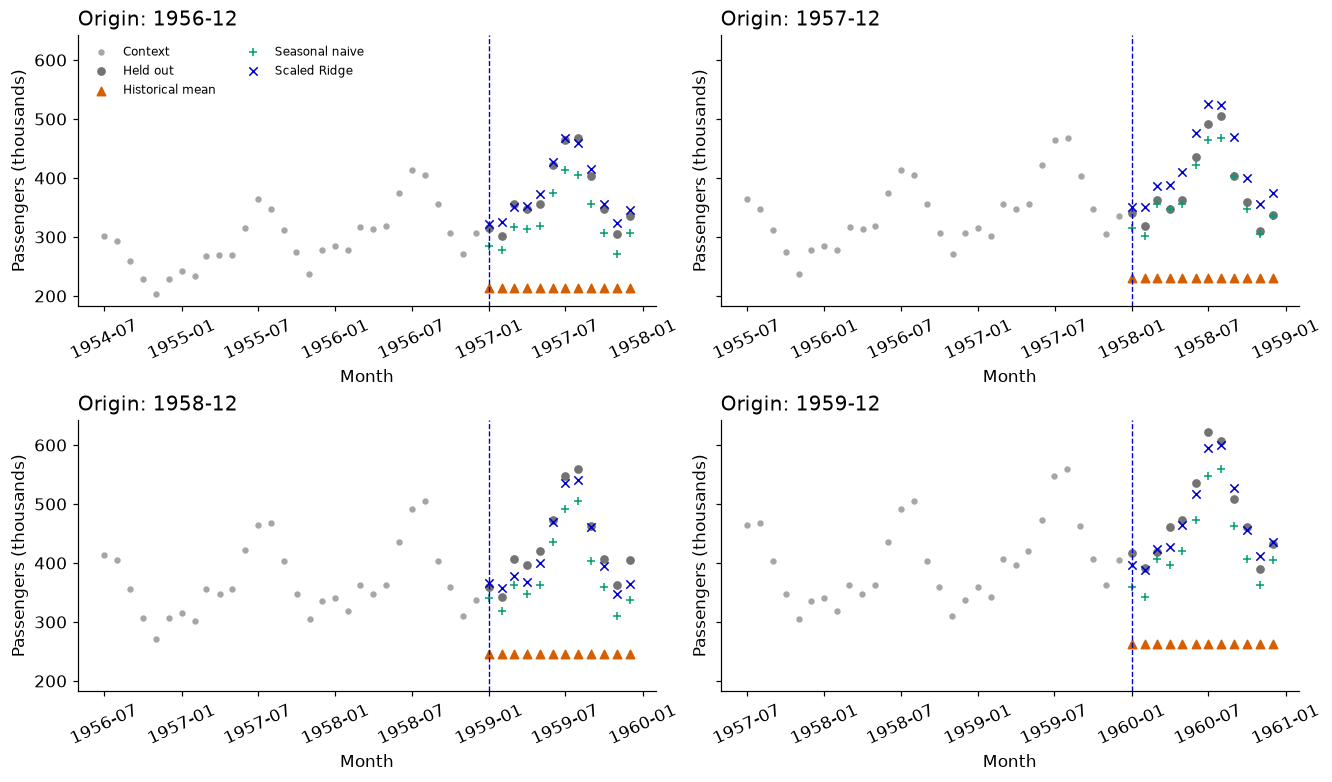

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True, layout='constrained')
colors = {'Historical mean': '#D55E00', 'Seasonal naive': '#009E73', 'Scaled Ridge': '#0000CC'}
markers = {'Historical mean': '^', 'Seasonal naive': '+', 'Scaled Ridge': 'x'}
for case_index, (ax, case) in enumerate(zip(axes.flat, cases)):
    context = case.task.context.iloc[-30:]
    ax.scatter(context.index.to_timestamp(), context.iloc[:, 0], color='0.65', s=10, label='Context')
    ax.scatter(case.observed.index.to_timestamp(), case.observed.iloc[:, 0],
               color='0.45', s=22, label='Held out')
    for model_name in models:
        forecast = forecasts[(case_index, model_name)]
        ax.scatter(forecast.index.to_timestamp(), forecast.point[:, 0], marker=markers[model_name],
                   s=30, color=colors[model_name], linewidths=1, label=model_name)
    ax.axvline(case.task.future_index[0].to_timestamp(), color='#0000CC', linestyle='--', linewidth=0.9)
    ax.set(title=f'Origin: {case.task.context.index[-1]}', xlabel='Month', ylabel='Passengers (thousands)')
    ax.tick_params(axis='x', labelrotation=25)
axes[0, 0].legend(fontsize=8, ncol=2)
plt.show()

## Do predictions track observed levels?

Plot actual versus predicted values for the same 48 held-out months. The diagonal marks exact agreement; points below it underpredict. This view pools the chosen windows only for inspection, not for independent-sample inference.

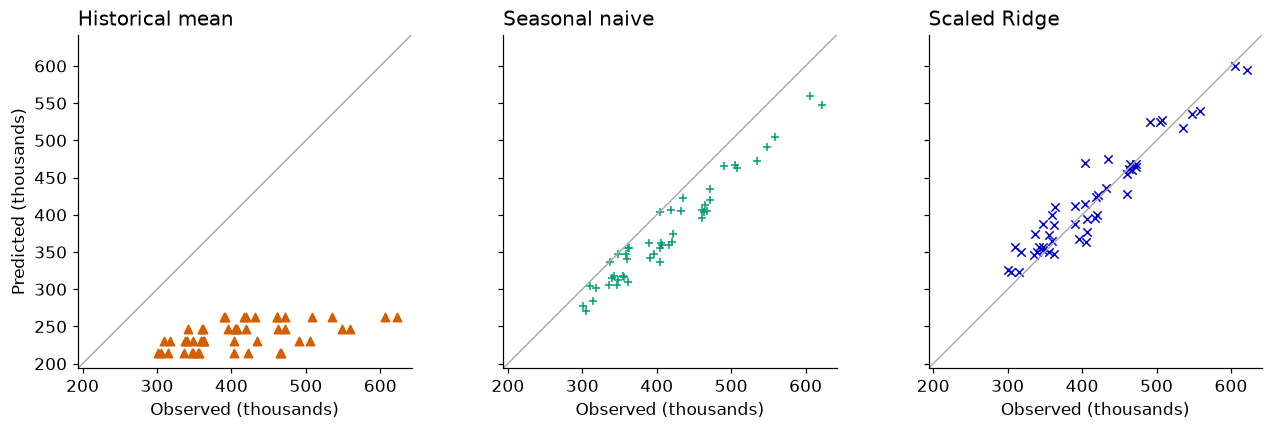

In [9]:
actual = np.concatenate([case.observed.iloc[:, 0].to_numpy() for case in cases])
all_predictions = {name: np.concatenate([forecasts[(i, name)].point[:, 0] for i in range(len(cases))])
                   for name in models}
minimum = min(actual.min(), min(values.min() for values in all_predictions.values()))
maximum = max(actual.max(), max(values.max() for values in all_predictions.values()))
limits = (minimum - 20, maximum + 20)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True, sharey=True, layout='constrained')
for ax, name in zip(axes, models):
    ax.plot(limits, limits, color='0.65', linewidth=0.9)
    ax.scatter(actual, all_predictions[name], marker=markers[name], s=30, color=colors[name], linewidths=1)
    ax.set(title=name, xlabel='Observed (thousands)', xlim=limits, ylim=limits, aspect='equal')
axes[0].set_ylabel('Predicted (thousands)')
plt.show()

The historical mean cannot follow high seasonal outcomes; its points flatten across observed levels. The other baselines can vary with the season, but departures from the diagonal remain visible. This diagnostic view makes no calibration or population-ranking claim.

Seasonal structure is visible in both the observations and the forecasts; a historical mean cannot follow its peaks. Compare each method against the same gray held-out dots, in original units.

## Check the fitted scaler

For one origin, verify that the cloned scaler sees exactly the context's lag rows and leaves supplied templates unfitted. This checks this adapter boundary, not arbitrary third-party feature code.

In [10]:
inspection_context = cases[-1].task.context
inspection_values = inspection_context.to_numpy()
inspection_lags = np.asarray([inspection_values[i - window:i].ravel()
                              for i in range(window, len(inspection_values))])
inspection_model = SklearnForecaster([scaler_template, ridge_template],
                                     window_length=window).fit(inspection_context)
fitted_scaler = inspection_model.models_[0].named_steps['step_0']
fitted_ridge = inspection_model.models_[0].named_steps['step_1']
assert fitted_scaler is not scaler_template and fitted_ridge is not ridge_template
assert fitted_scaler.n_samples_seen_ == len(inspection_context) - window
np.testing.assert_allclose(fitted_scaler.mean_, inspection_lags.mean(axis=0))
assert not hasattr(scaler_template, 'mean_') and not hasattr(ridge_template, 'coef_')
np.testing.assert_allclose(inspection_model.predict(cases[-1].task.future_index).point,
                           forecasts[(len(cases) - 1, 'Scaled Ridge')].point)
display(pd.DataFrame([{'training_context_rows': len(inspection_context),
                       'scaler_training_rows': int(fitted_scaler.n_samples_seen_),
                       'original_scaler_fitted': hasattr(scaler_template, 'mean_'),
                       'original_ridge_fitted': hasattr(ridge_template, 'coef_')}]))


,training_context_rows,scaler_training_rows,original_scaler_fitted,original_ridge_fitted
0,132,120,False,False


## Put a distribution around the final origin

The fitted Gaussian AR(1) supplies innovation uncertainty but omits parameter uncertainty and explicit seasonality. Its bands are 80% **marginal** intervals, not an 80% simultaneous trajectory region. A real reference covariance is unavailable, so that comparison must remain unsupported.

In [11]:
real_case = cases[-1]
probabilistic_pipeline = Pipeline(GaussianAR1Forecaster(n_samples=256, seed=17))
probabilistic_forecast = probabilistic_pipeline.predict(real_case.task.context,
                                                       real_case.task.future_index)
probabilistic_result = evaluate_forecast(real_case, probabilistic_forecast,
                                         check_dependence=True)
probabilistic_result.manifest['model'] = 'GaussianAR1Forecaster'
assert probabilistic_forecast.validate(real_case.task) == []
assert probabilistic_forecast.samples.shape == (256, 12, 1)
assert probabilistic_forecast.quantiles.shape == (12, 1, 3)
assert 'mean_reference_mse' not in probabilistic_result.metrics
covariance_diagnostic = next(d for d in probabilistic_result.diagnostics
                             if d.name == 'reference_covariance')
assert covariance_diagnostic.status == 'UNSUPPORTED'
display(pd.Series(probabilistic_result.metrics, name='Final-origin descriptive scores'))


mse                          14909.135232
mae                             95.093927
mase                             3.948432
pinball                         31.664372
interval_coverage                0.666667
interval_nominal_coverage        0.800000
interval_width                 176.971493
crps                            69.289287
energy_score                   302.296094
variogram_score                 20.241216
Name: Final-origin descriptive scores, dtype: float64

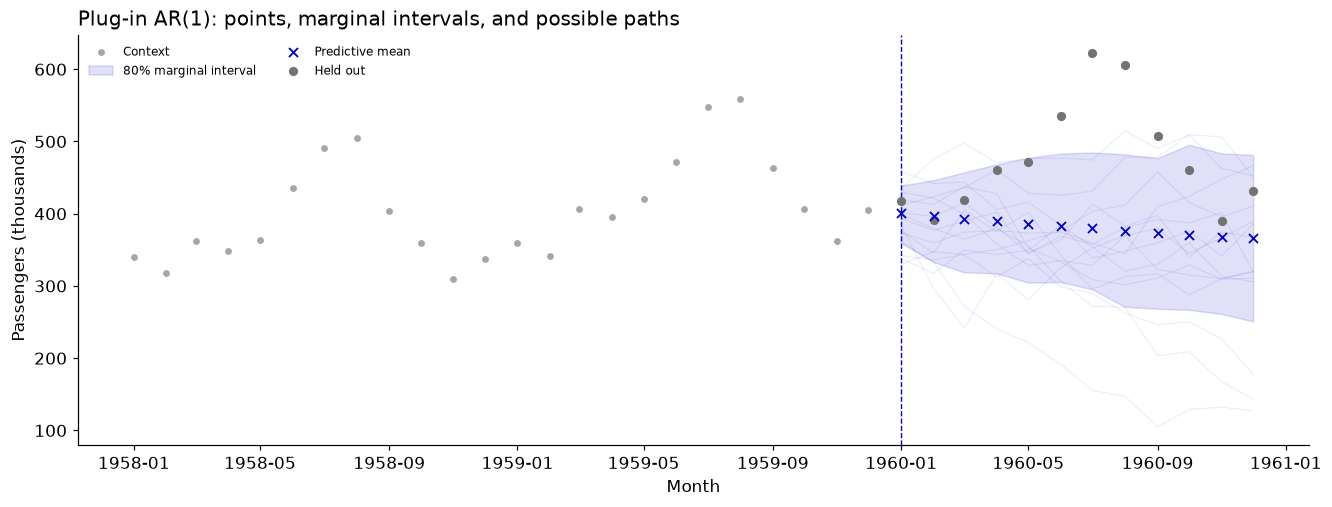

In [12]:
forecast = probabilistic_forecast
future_dates = forecast.index.to_timestamp()
context_tail = real_case.task.context.iloc[-24:]
fig, ax = plt.subplots(figsize=(12, 4.5), layout='constrained')
ax.scatter(context_tail.index.to_timestamp(), context_tail.iloc[:, 0],
           color='0.65', s=12, label='Context')
for path in forecast.samples[:15, :, 0]:
    ax.plot(future_dates, path, color='#0000CC', alpha=0.08, linewidth=0.7)
ax.fill_between(future_dates, forecast.quantiles[:, 0, 0], forecast.quantiles[:, 0, -1],
                color='#0000CC', alpha=0.12, label='80% marginal interval')
ax.scatter(future_dates, forecast.point[:, 0], color='#0000CC', marker='x', s=35,
           linewidths=1.2, label='Predictive mean', zorder=4)
ax.scatter(real_case.observed.index.to_timestamp(), real_case.observed.iloc[:, 0],
           color='0.45', s=25, label='Held out', zorder=3)
ax.axvline(future_dates[0], color='#0000CC', linestyle='--', linewidth=0.9)
ax.set(title='Plug-in AR(1): points, marginal intervals, and possible paths',
       xlabel='Month', ylabel='Passengers (thousands)')
ax.legend(fontsize=8, ncol=2)
plt.show()

Blue crosses summarize location; the band and faint lines represent a distribution and complete sample paths. Compare their shape with the seasonal held-out dots before interpreting any aggregate score.

Pinball and empirical CRPS score marginal uncertainty; energy and variogram scores use the complete 12-month vector. One path's dependent coverage indicators cannot establish calibration, even if their average equals the nominal level.

In [13]:
display(pd.DataFrame([{'check': d.name, 'status': d.status, 'message': d.message}
                      for d in probabilistic_result.diagnostics
                      if d.name in {'interval_coverage', 'sample_scores', 'reference_covariance'}]))
inside = ((real_case.observed.to_numpy() >= probabilistic_forecast.quantiles[..., 0]) &
          (real_case.observed.to_numpy() <= probabilistic_forecast.quantiles[..., -1]))
print(f'Observed coverage: {int(inside.sum())}/{inside.size} months inside the interval')
print(f'Nominal marginal coverage: {probabilistic_result.metrics["interval_nominal_coverage"]:.0%}')


,check,status,message
0,interval_coverage,INCONCLUSIVE,One-path coverage across possibly dependent co...
1,sample_scores,INCONCLUSIVE,Empirical marginal and joint scores are descri...
2,reference_covariance,UNSUPPORTED,Predictive samples and a reference covariance ...


Observed coverage: 8/12 months inside the interval
Nominal marginal coverage: 80%


## Retain the data and evaluation design

Save the JSON evidence with the checked-in CSV and this notebook. Its source checksum, chronological origins, and model settings are recorded, but automatic replay cannot reconstruct this real-data sklearn study from JSON alone.

In [14]:
real_report = TestReport(cases=[*results.values(), probabilistic_result], metadata={
    'dataset': 'AirPassengers', 'source_sha256': source_sha256,
    'origin_lengths': list(origin_lengths), 'horizon': horizon,
    'point_models': {'mean': {}, 'seasonal_naive': {'period': 12},
                     'scaled_ridge': {'window_length': window, 'alpha': 1.0}},
    'probabilistic_example': {'model': 'GaussianAR1Forecaster', 'n_samples': 256, 'seed': 17},
    'automatic_replay_supported': False,
    'reproduction': 'Run this notebook against the checked-in CSV with matching dependencies.',
    'interpretation': 'Descriptive ordered windows from one series; no IID uncertainty claim.',
})
serialized_report = real_report.to_json()
assert json.loads(serialized_report)['summary']['cases'] == 13
display(pd.Series(real_report.summary, name='Real-data report summary'))
print('Report JSON size:', len(serialized_report.encode('utf-8')), 'bytes')


cases                                                           13
diagnostics                                                     54
status_counts    {'PASS': 13, 'FAIL': 0, 'INCONCLUSIVE': 16, 'U...
failed_cases                                                     0
Name: Real-data report summary, dtype: object

Report JSON size: 24080 bytes


## Change one thing

- Add a last-value baseline at the same four origins.
- Predeclare another window or Ridge penalty; reserve separate origins before claiming an improvement.
- Use your own regularly indexed data, preserving target units, chronological splits, and training-only scaling.

**Scope.** Nonoverlapping holdouts from one series do not justify IID intervals or population-wide claims. Probabilistic samples use a finite plug-in ensemble, and no true mean/covariance is supplied.

For multiple targets, continue with [multivariate forecasting](21_multivariate_forecasting.ipynb) and [joint uncertainty](22_multivariate_uncertainty.ipynb). For independent controlled replications, see [capability sweeps](25_capability_sweeps.ipynb).